# Stage 5: imagination and the causal test

For test patients with observed MAP < 70 at hour 24, each world model imagines the next 12 hours from the prior only, once with vasopressors on (u=1) and once off (u=0), 50 samples each. The predicted effect is compared with the true effect from rerunning the simulator from the patient's real hidden state at hour 24 with the same noise in both arms.

All the logic lives in `src/rollout.py`; this notebook just runs it and shows the results.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))
from IPython.display import Image, display
import rollout

In [2]:
results = [rollout.run_causal_test(name) for name in ('policy', 'explore')]
print(rollout.summary_table(results))

model       n                   +1 h                   +3 h                   +6 h                  +12 h
               pred (p10..p90) | true  pred (p10..p90) | true  pred (p10..p90) | true  pred (p10..p90) | true
policy    166    2.6 ( 1.8.. 3.5) |  3.0    9.1 ( 8.0..10.2) | 11.7   15.8 (13.9..17.5) | 24.2   22.7 (19.8..25.3) | 40.9
explore    33    2.6 ( 1.9.. 3.3) |  3.0    9.8 ( 8.6..11.1) | 11.7   18.6 (16.3..21.4) | 24.2   31.4 (27.0..35.2) | 40.9


## Predicted vs true effect

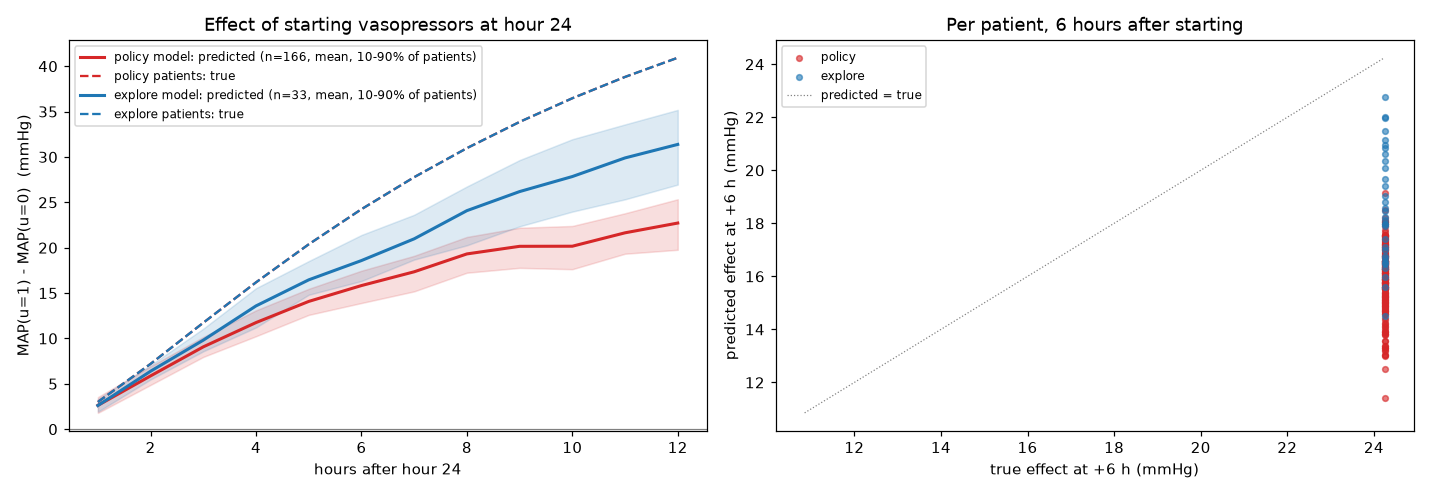

In [3]:
rollout.plot_effects(results)
display(Image(rollout.FIG / 'causal_effect.png'))

## Example patients: both imagined arms vs the true trajectories

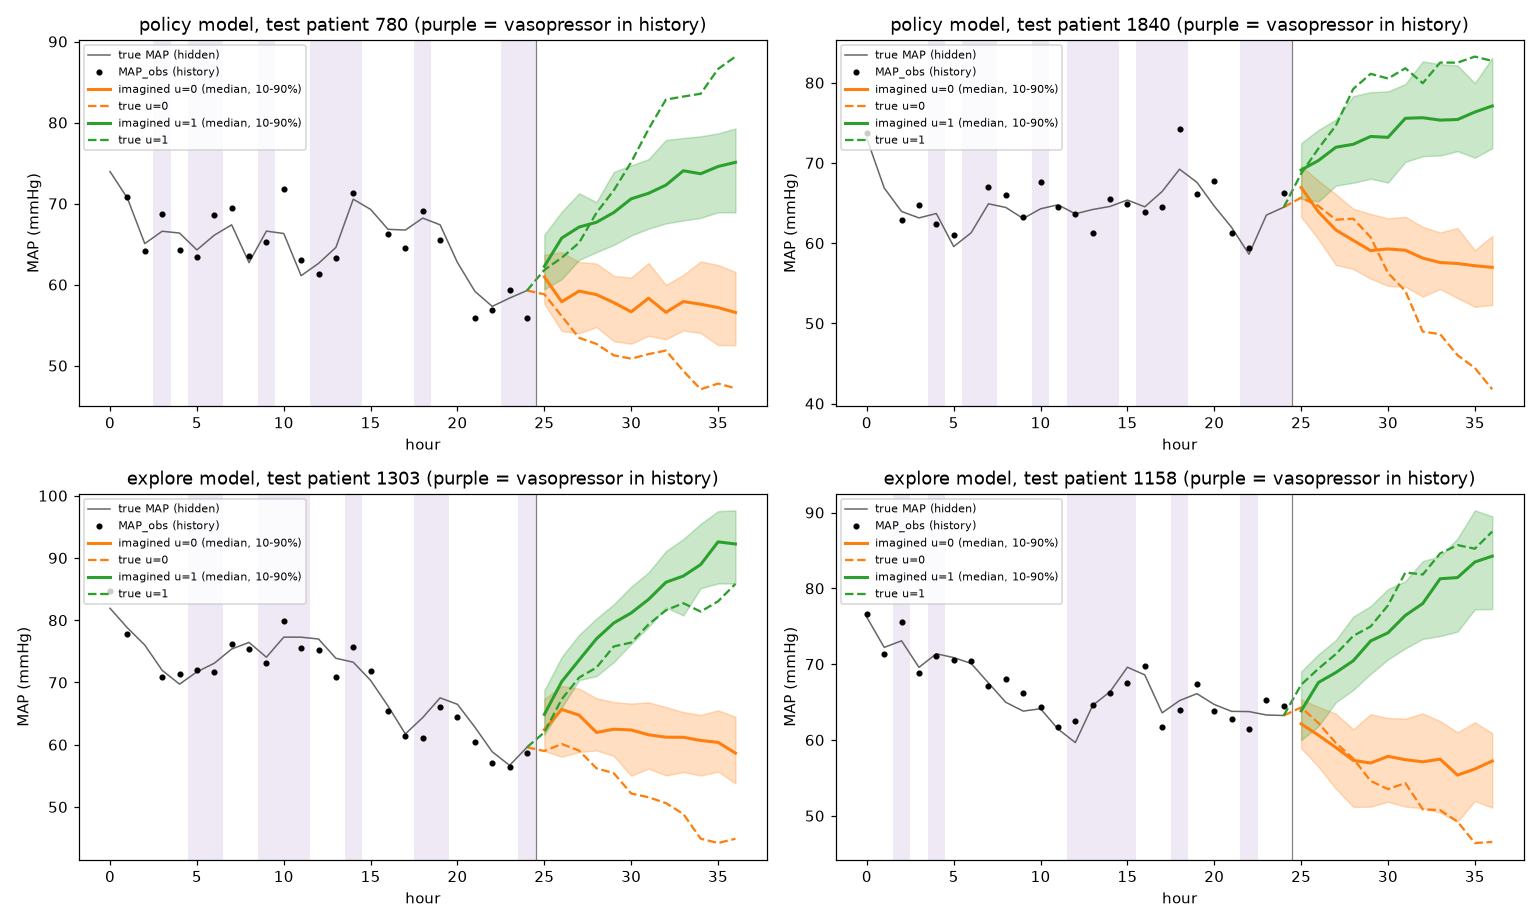

In [4]:
rollout.plot_examples(results)
display(Image(rollout.FIG / 'rollout_examples.png'))